In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

In [26]:
df = pd.read_csv('/content/genres_v2.csv')
df.head()

/tmp/ipykernel_3255/705445000.py:1: DtypeWarning: Columns (19) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('/content/genres_v2.csv')


,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,...,id,uri,track_href,analysis_url,duration_ms,time_signature,genre,song_name,Unnamed: 0,title
0,0.831,0.814,2,-7.364,1,0.4200,0.0598,0.013400,0.0556,0.3890,...,2Vc6NJ9PW9gD9q343XFRKx,spotify:track:2Vc6NJ9PW9gD9q343XFRKx,https://api.spotify.com/v1/tracks/2Vc6NJ9PW9gD...,https://api.spotify.com/v1/audio-analysis/2Vc6...,124539,4,Dark Trap,Mercury: Retrograde,NaN,NaN
1,0.719,0.493,8,-7.230,1,0.0794,0.4010,0.000000,0.1180,0.1240,...,7pgJBLVz5VmnL7uGHmRj6p,spotify:track:7pgJBLVz5VmnL7uGHmRj6p,https://api.spotify.com/v1/tracks/7pgJBLVz5Vmn...,https://api.spotify.com/v1/audio-analysis/7pgJ...,224427,4,Dark Trap,Pathology,NaN,NaN
2,0.850,0.893,5,-4.783,1,0.0623,0.0138,0.000004,0.3720,0.0391,...,0vSWgAlfpye0WCGeNmuNhy,spotify:track:0vSWgAlfpye0WCGeNmuNhy,https://api.spotify.com/v1/tracks/0vSWgAlfpye0...,https://api.spotify.com/v1/audio-analysis/0vSW...,98821,4,Dark Trap,Symbiote,NaN,NaN
3,0.476,0.781,0,-4.710,1,0.1030,0.0237,0.000000,0.1140,0.1750,...,0VSXnJqQkwuH2ei1nOQ1nu,spotify:track:0VSXnJqQkwuH2ei1nOQ1nu,https://api.spotify.com/v1/tracks/0VSXnJqQkwuH...,https://api.spotify.com/v1/audio-analysis/0VSX...,123661,3,Dark Trap,ProductOfDrugs (Prod. The Virus and Antidote),NaN,NaN
4,0.798,0.624,2,-7.668,1,0.2930,0.2170,0.000000,0.1660,0.5910,...,4jCeguq9rMTlbMmPHuO7S3,spotify:track:4jCeguq9rMTlbMmPHuO7S3,https://api.spotify.com/v1/tracks/4jCeguq9rMTl...,https://api.spotify.com/v1/audio-analysis/4jCe...,123298,4,Dark Trap,Venom,NaN,NaN


In [27]:
df.info()
df.describe()
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42305 entries, 0 to 42304
Data columns (total 22 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   danceability      42305 non-null  float64
 1   energy            42305 non-null  float64
 2   key               42305 non-null  int64  
 3   loudness          42305 non-null  float64
 4   mode              42305 non-null  int64  
 5   speechiness       42305 non-null  float64
 6   acousticness      42305 non-null  float64
 7   instrumentalness  42305 non-null  float64
 8   liveness          42305 non-null  float64
 9   valence           42305 non-null  float64
 10  tempo             42305 non-null  float64
 11  type              42305 non-null  object 
 12  id                42305 non-null  object 
 13  uri               42305 non-null  object 
 14  track_href        42305 non-null  object 
 15  analysis_url      42305 non-null  object 
 16  duration_ms       42305 non-null  int64 

,0
danceability,0
energy,0
key,0
loudness,0
mode,0
speechiness,0
acousticness,0
instrumentalness,0
liveness,0
valence,0


In [28]:
features=['danceability','energy','loudness','speechiness','acousticness',
'instrumentalness','liveness','valence','tempo']

music=df[['song_name','genre']+features].dropna()
music.head()

,song_name,genre,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
0,Mercury: Retrograde,Dark Trap,0.831,0.814,-7.364,0.4200,0.0598,0.013400,0.0556,0.3890,156.985
1,Pathology,Dark Trap,0.719,0.493,-7.230,0.0794,0.4010,0.000000,0.1180,0.1240,115.080
2,Symbiote,Dark Trap,0.850,0.893,-4.783,0.0623,0.0138,0.000004,0.3720,0.0391,218.050
3,ProductOfDrugs (Prod. The Virus and Antidote),Dark Trap,0.476,0.781,-4.710,0.1030,0.0237,0.000000,0.1140,0.1750,186.948
4,Venom,Dark Trap,0.798,0.624,-7.668,0.2930,0.2170,0.000000,0.1660,0.5910,147.988


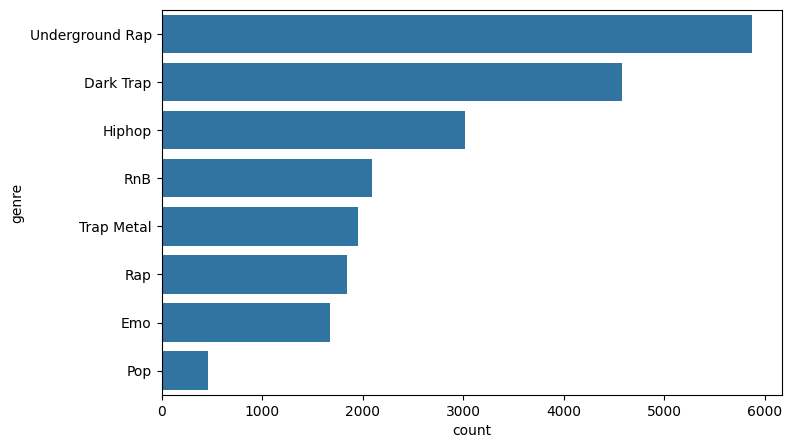

In [29]:
plt.figure(figsize=(8,5))
sns.countplot(y='genre',data=music,order=music['genre'].value_counts().index)
plt.show()

In [30]:
scaler=StandardScaler()
X_scaled=scaler.fit_transform(music[features])

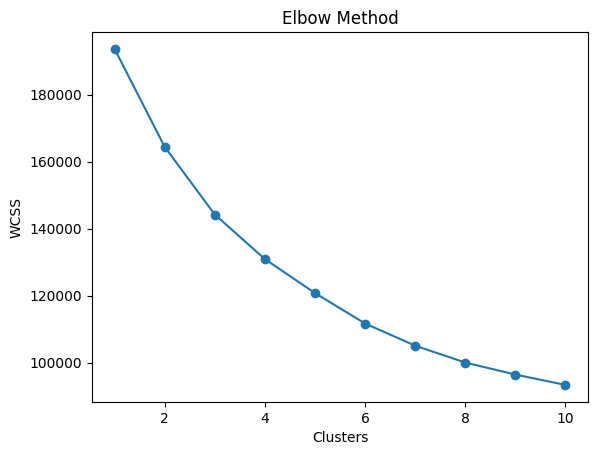

In [31]:
wcss=[]
for k in range(1,11):
    km=KMeans(n_clusters=k,random_state=42,n_init=10)
    km.fit(X_scaled)
    wcss.append(km.inertia_)

plt.plot(range(1,11),wcss,marker='o')
plt.xlabel('Clusters')
plt.ylabel('WCSS')
plt.title('Elbow Method')
plt.show()

In [32]:
kmeans=KMeans(n_clusters=8,random_state=42,n_init=10)
music['Cluster']=kmeans.fit_predict(X_scaled)
music.head()

,song_name,genre,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,Cluster
0,Mercury: Retrograde,Dark Trap,0.831,0.814,-7.364,0.4200,0.0598,0.013400,0.0556,0.3890,156.985,5
1,Pathology,Dark Trap,0.719,0.493,-7.230,0.0794,0.4010,0.000000,0.1180,0.1240,115.080,3
2,Symbiote,Dark Trap,0.850,0.893,-4.783,0.0623,0.0138,0.000004,0.3720,0.0391,218.050,4
3,ProductOfDrugs (Prod. The Virus and Antidote),Dark Trap,0.476,0.781,-4.710,0.1030,0.0237,0.000000,0.1140,0.1750,186.948,0
4,Venom,Dark Trap,0.798,0.624,-7.668,0.2930,0.2170,0.000000,0.1660,0.5910,147.988,5


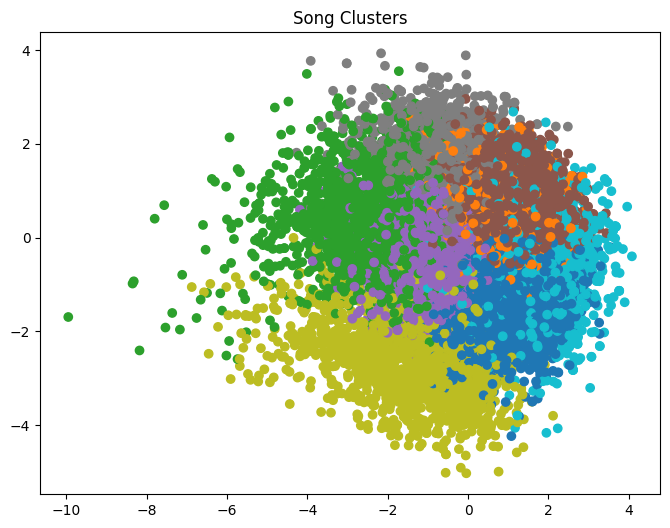

In [33]:
pca=PCA(n_components=2)
pca_data=pca.fit_transform(X_scaled)
plt.figure(figsize=(8,6))
plt.scatter(pca_data[:,0],pca_data[:,1],c=music['Cluster'],cmap='tab10')
plt.title('Song Clusters')
plt.show()

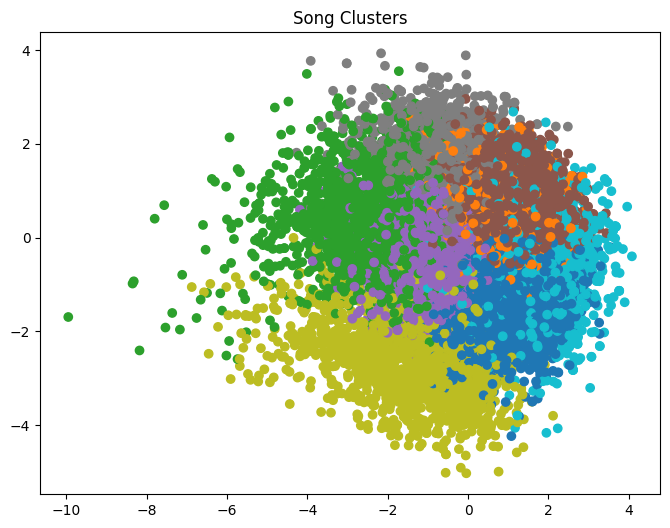

In [34]:
pca=PCA(n_components=2)
pca_data=pca.fit_transform(X_scaled)
plt.figure(figsize=(8,6))
plt.scatter(pca_data[:,0],pca_data[:,1],c=music['Cluster'],cmap='tab10')
plt.title('Song Clusters')
plt.show()

In [35]:
def recommend_song(song_name,n=5):
    if song_name not in music['song_name'].values:
        print('Song not found')
        return
    cluster=music.loc[music['song_name']==song_name,'Cluster'].iloc[0]
    rec=music[(music['Cluster']==cluster)&(music['song_name']!=song_name)]
    return rec[['song_name','genre']].head(n)

recommend_song('Black Helicopters')

,song_name,genre
2,Symbiote,Dark Trap
8,I Put My Dick in Your Mental,Dark Trap
19,Paris,Dark Trap
39,Kybalion,Dark Trap
40,Killer,Dark Trap
